# 03. FoldedVision AI — Lens YOLO26n 결함 검출 (팀 공통 모델 버전)

02 노트북은 직접 설계한 CNN과 U-Net을 썼습니다. 이 노트북은 팀원들과 같은 **YOLO26n**(Ultralytics, COCO 사전학습)으로 Lens 결함을 **상자(위치) + 결함 종류 5가지**로 검출합니다. **같은 사진 분할, 같은 test 구역**으로 02의 CNN과 공정하게 비교합니다.

| 단계 | 내용 |
|---|---|
| 1. 데이터 준비 | 02와 같은 셀(렌즈 단위 분할, 작업 배율, 256 구역 정답)을 그대로 씁니다 |
| 2. YOLO 데이터 | 줄인 사진을 **640×640 조각**으로 잘라 YOLO 형식(사진 + 상자 txt)으로 저장합니다 |
| 3. 학습 | `yolo26n.pt`에서 이어서 학습합니다(CPU). 저장 모델이 있으면 다시 학습하지 않습니다 |
| 4. 검출 평가 | test 조각에서 mAP50, mAP50-95, 결함 종류별 AP50 |
| 5. CNN과 비교 | 256 구역 점수 = 그 구역에 걸친 YOLO 상자 신뢰도의 최댓값 → 02와 같은 지표(AP, Recall 95% 경계의 정상 구역 오검출률) |
| 6. 결과 저장 | 사진 판정 OK / REVIEW / NG, 팀 통합용 CSV·JSON, `predict_lens_yolo(image)` |

**왜 640 조각으로 자르나요?** 원본 사진은 최대 3500×3500입니다. YOLO 기본 입력 640으로 사진 전체를 줄이면 20픽셀 남짓한 결함이 3~4픽셀로 사라집니다. 그래서 02와 같은 배율로 줄인 뒤 640 조각으로 잘라 결함 크기를 지킵니다.

**준비:** PyCharm 터미널(`.venv` 켜진 상태)에서 한 번만 실행하세요.
```
pip install ultralytics
```
처음 학습할 때 `yolo26n.pt`(사전학습 가중치)를 인터넷에서 자동으로 받습니다.

> 공개 데이터 기술 검증(PoC)입니다. 자화전자 실제 생산 데이터·생산라인 성능이 아닙니다.

In [1]:
# ── PART 01. 실행 설정 ──
from pathlib import Path
import os
NOTEBOOK_ID = "03"
DATASET_NAME = "Lens"
IMAGE_SIZE = 256  # 02와 같은 256 구역으로 비교하기 위해 유지
BATCH_SIZE = 16
SEED = 42
RUN_MODE = os.environ.get("FOLDEDVISION_MODE", "full")  # "quick" 또는 "full"
assert RUN_MODE in ("quick", "full")
USE_SAVED_MODELS = True  # 데이터·설정이 같은 저장 YOLO 모델이 있으면 다시 학습하지 않음

# YOLO 설정
YOLO_MODEL = "yolo26n.pt"  # 팀 공통 모델(COCO 사전학습)
YOLO_IMGSZ = 640  # YOLO 입력 크기
YOLO_TILE = 640  # 줄인 사진을 자르는 조각 크기
YOLO_STRIDE = 480  # 조각을 3/4씩 겹쳐 자름(경계에 걸친 결함 보호)
YOLO_TILE_VALID_MIN = 0.05  # 렌즈 면이 5% 미만인 조각(거의 검은 배경)은 쓰지 않음
YOLO_BG_RATIO = 1.0  # train: 결함 없는 조각을 결함 조각 수의 1배까지 함께 학습(오검출 줄이기)
YOLO_MIN_BOX = 8  # 상자 한 변이 이보다 작으면 중심을 기준으로 이 크기까지 넓힘(가는 실 결함 보호)
YOLO_EPOCHS = 2 if RUN_MODE == "quick" else 60
YOLO_PATIENCE = 15  # validation mAP가 이 횟수 동안 좋아지지 않으면 조기 종료
YOLO_BATCH = 8
YOLO_DEVICE = "cpu"
YOLO_CONF_MIN = 0.001  # 평가용: 낮은 신뢰도 상자까지 모두 받아 경계는 validation으로 정함
ENABLE_GRADIO = False  # True: 로컬(127.0.0.1:7863) YOLO 검사 화면
MODEL_VERSION_TAG = "v1"

### 경로와 공통 규칙
- `full` 결과는 `models/`, `outputs/`에 지시서의 이름 그대로 저장합니다.
- `quick` 결과는 `models/quick/`, `outputs/quick/`에 따로 저장합니다. 최종 결과를 덮어쓰지 않기 위해서입니다.

| 이름 | 값 | 의미 |
|---|---|---|
| `IMAGE_SIZE` | 256 | 모델 입력 = 256×256 RGB **구역(patch)** |
| `LENS_TARGET_DEFECT_PX` | 20 | 줄인 사진에서 결함 한 변이 약 20픽셀이 되도록 사진 크기 묶음별 배율을 정합니다. 사진 전체를 256으로 줄이면 작은 결함이 사라지기 때문입니다. |
| `STRIDE` | 192 | 구역을 3/4씩 옮깁니다. 겹치게 해서 경계에 걸친 결함을 놓치지 않습니다. |
| `VALID_MIN` | 0.2 | 렌즈 면(밝은 영역)이 20% 미만인 구역(거의 검은 배경)은 검사하지 않습니다. |
| `MIN_DEFECT_PX` | 4 | 구역 안 결함 픽셀이 4개 이상이면 불량 구역, 0개면 정상 구역, 1~3개(가장자리에 살짝 걸침)는 애매해서 학습·평가에서 뺍니다. |

In [2]:
# ── 공통 경로·규칙 (두 노트북 동일) ──
ROOT = Path.cwd().resolve()  # FoldedVision_Lens 폴더에서 실행하세요.
QUICK = RUN_MODE == "quick"
MODEL_DIR = ROOT / ("models/quick" if QUICK else "models")
OUT_DIR = ROOT / ("outputs/quick" if QUICK else "outputs")
FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR = OUT_DIR / "figures", OUT_DIR / "predictions", OUT_DIR / "metrics", OUT_DIR / "integration"
PROCESSED = ROOT / "data/processed"
for folder in [ROOT / "data/archives", ROOT / "data/raw", PROCESSED, MODEL_DIR, FIG_DIR, PRED_DIR, MET_DIR, INTEG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)  # 기존 파일은 지우지 않습니다.

LENS_TARGET_DEFECT_PX = 20
PATCH = IMAGE_SIZE  # 모델 입력 구역 한 변
STRIDE = PATCH * 3 // 4
VALID_MIN = 0.2
MIN_DEFECT_PX = 4
NEG_PER_POS = 2.0  # 학습 때 정상 구역을 불량 구역의 2배만 뽑습니다(전부 쓰면 정상이 너무 많음).
INTERNAL_VAL_FRACTION = 0.2  # 공식 train 안에서 내부 검증으로 떼는 비율(렌즈 묶음 단위)
RECALL_TARGET = 0.95  # NG 경계: 검증에서 불량 구역 Recall 95% 이상
REVIEW_RECALL = 0.99  # OK 경계: 검증에서 불량 구역 Recall 99% 이상(더 보수적) → 사이 구간이 REVIEW
QUICK_LIMIT = {"train": 8, "validation": 4, "test": 6}  # quick 모드에서 쓰는 사진 수
print("실행 모드:", RUN_MODE, "/ 모델 폴더:", MODEL_DIR, "/ 결과 폴더:", OUT_DIR)

실행 모드: full / 모델 폴더: C:\Project\Ai_Source\FoldedVision_Lens\models / 결과 폴더: C:\Project\Ai_Source\FoldedVision_Lens\outputs


In [3]:
# 공통 도구: 파일 지문·한글 경로 이미지 읽기·JSON 저장 (TensorFlow 불필요)
import sys, json, tarfile, shutil, hashlib, time, platform
from collections import Counter, defaultdict
from datetime import datetime, timezone, timedelta
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
KST = timezone(timedelta(hours=9))
plt.rcParams["font.family"] = "Malgun Gothic" if platform.system() == "Windows" else "DejaVu Sans"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False

def save_json(path, value):
    # 한글·들여쓰기 유지. NumPy 숫자도 일반 숫자로 바꿔 저장합니다.
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")

def sha256_file(path):
    # 파일 내용 지문: 같은 파일인지, 모델이 바뀌었는지 확인합니다.
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_rgb(path):
    # OpenCV는 BGR로 읽으므로 RGB로 바꿉니다. np.fromfile+imdecode는 한글 경로에서도 동작합니다.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"이미지 읽기 실패(손상 가능): {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def save_png(path, rgb_or_gray):
    # 한글 경로에도 저장되도록 imencode + tofile을 씁니다.
    array = cv2.cvtColor(rgb_or_gray, cv2.COLOR_RGB2BGR) if rgb_or_gray.ndim == 3 else rgb_or_gray
    cv2.imencode(".png", array)[1].tofile(str(path))

## 데이터 준비 — Lens.tar.gz 찾기와 안전한 압축 해제
1. **이미 풀린 폴더를 먼저 찾습니다.** `data` 아래에 Lens 폴더(`train/val/inference` + `_annotations.coco.json`)가 있으면 그대로 다시 씁니다. 압축을 다시 풀지 않습니다.
2. **없으면 압축파일을 찾습니다.** 찾는 순서는 현재 폴더 → `data/archives` → `data/raw` → `data` → Windows `다운로드` 폴더입니다. 이름은 `Lens.tar.gz`, `Lens_tar.gz` 둘 다 인식합니다. `data/archives` 밖에서 찾은 파일은 원본을 그대로 두고 **사본**을 `data/archives`에 둡니다.
3. **안전하게 풉니다.**
   - 압축 안 경로가 폴더 밖을 가리키거나(`..`, 절대경로) 링크·장치 파일이 있으면 멈춥니다.
   - 맥 메타데이터(`._*`)는 풀지 않습니다.
   - 임시 폴더에 다 푼 뒤에만 `data/raw/Lens_extracted`로 이름을 바꿉니다.
4. **어디에도 없으면** Hugging Face 공식 저장소에서 `Lens.tar.gz` 하나만 받습니다. 이 데이터셋은 이용 조건 동의가 필요한 '게이트' 데이터입니다. `huggingface-cli login`으로 로그인하고 웹에서 조건에 동의한 경우에만 받아집니다.

In [4]:
# Lens 데이터 폴더 찾기 → 없으면 압축 해제 → 그래도 없으면 공식 저장소에서 받기
HF_REPO, HF_FILE = "VISION-Workshop/VISION-Datasets", "Lens.tar.gz"

def find_lens_dataset_dirs(base):
    found = set()
    for annotation in Path(base).rglob("_annotations.coco.json"):
        top = annotation.parent.parent
        if annotation.parent.name == "train" and (top / "val/_annotations.coco.json").exists() and not top.name.startswith("."):
            found.add(top.resolve())
    return sorted(found)

def find_archives():
    places = [ROOT, ROOT / "data/archives", ROOT / "data/raw", ROOT / "data", Path.home() / "Downloads"]
    by_hash = {}
    for place in places:
        if not place.is_dir():
            continue
        for path in place.glob("Lens*"):
            if path.is_file() and (path.name.endswith(".gz") or path.name.endswith(".tgz")):
                by_hash.setdefault(sha256_file(path), path.resolve())  # 같은 내용이면 한 번만
    return by_hash

def safe_extract_tar(archive, destination):
    destination = Path(destination).resolve()
    with tarfile.open(archive, "r:*") as pack:
        members = pack.getmembers()
        if len(members) > 20000 or sum(m.size for m in members) > 5 * 1024**3:
            raise ValueError("예상하지 못한 압축 항목 수 또는 크기")
        for member in members:  # 쓰기 전에 전부 검사
            name = member.name.replace(chr(92), "/")
            if Path(name).is_absolute() or ".." in Path(name).parts or ":" in name:
                raise ValueError(f"압축파일 경로 이탈: {member.name}")
            if member.issym() or member.islnk() or member.isdev():
                raise ValueError(f"링크·장치 파일은 허용하지 않습니다: {member.name}")
        written = 0
        for member in members:
            if not member.isfile() or Path(member.name).name.startswith("._"):
                continue
            target = (destination / member.name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("압축파일 경로 이탈")
            target.parent.mkdir(parents=True, exist_ok=True)
            with pack.extractfile(member) as source, target.open("wb") as stream:
                shutil.copyfileobj(source, stream, length=1024 * 1024)
            written += 1
    return written

def download_from_hf():
    try:
        from huggingface_hub import hf_hub_download
    except ImportError:
        raise FileNotFoundError("Lens.tar.gz가 없습니다. 공식 VISION-Datasets에서 Lens.tar.gz를 받아 data/archives에 넣거나, pip install huggingface_hub 후 로그인하세요.")
    try:
        return Path(hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=ROOT / "data/archives"))
    except Exception as error:
        raise FileNotFoundError(f"공식 저장소 다운로드 실패({type(error).__name__}). 이용 조건 동의·로그인이 필요한 데이터셋입니다: {error}")

def prepare_lens():
    existing = find_lens_dataset_dirs(ROOT / "data")
    archives = find_archives()
    if len(archives) > 1:
        raise ValueError("내용이 다른 Lens 압축파일이 여러 개입니다: " + ", ".join(map(str, archives.values())))
    archive_info = None
    if archives:
        archive_hash, archive = next(iter(archives.items()))
        if archive.parent != (ROOT / "data/archives").resolve():
            kept = ROOT / "data/archives" / ("Lens.tar.gz" if archive.name.endswith(".gz") else archive.name)
            if not kept.exists():
                shutil.copy2(archive, kept)  # 원본은 두고 사본을 프로젝트에 보관
            archive = kept
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": archive_hash}
    if len(existing) == 1:
        return existing[0], {"how": "이미 풀린 폴더 재사용", "archive": archive_info}
    if len(existing) > 1:
        raise ValueError("Lens 폴더가 여러 곳에 있습니다:\n" + "\n".join(map(str, existing)))
    if archive_info is None:
        archive = download_from_hf()
        archive_info = {"path": str(archive.relative_to(ROOT)), "bytes": archive.stat().st_size, "sha256": sha256_file(archive), "source": "huggingface"}
    extract_root = (ROOT / "data/raw/Lens_extracted").resolve()
    if extract_root.exists():
        raise ValueError(f"{extract_root} 가 있지만 Lens 구조가 아닙니다. 확인 후 이름을 바꿔 주세요(자동 삭제 안 함).")
    temporary = extract_root.with_name(".Lens_extracting")
    if temporary.exists():
        shutil.rmtree(temporary)  # 이전에 중단된 '임시' 해제본만 지웁니다.
    written = safe_extract_tar(ROOT / archive_info["path"], temporary)
    temporary.rename(extract_root)
    save_json(extract_root / ".complete.json", {**archive_info, "files_written": written, "extracted_at": datetime.now(KST).isoformat()})
    found = find_lens_dataset_dirs(extract_root)
    if len(found) != 1:
        raise ValueError("압축 안에서 Lens train/val 구조를 찾지 못했습니다.")
    return found[0], {"how": "지금 압축 해제", "files_written": written, "archive": archive_info}

LENS_DATA_DIR, LENS_SOURCE = prepare_lens()
save_json(MET_DIR / "lens_acquisition.json", {"dataset_dir": str(LENS_DATA_DIR), "official_source": HF_REPO + " / " + HF_FILE, **LENS_SOURCE})
print("Lens 데이터 폴더:", LENS_DATA_DIR, "/", LENS_SOURCE["how"])

Lens 데이터 폴더: C:\Project\Ai_Source\FoldedVision_Lens\data\Lens\Lens / 이미 풀린 폴더 재사용


## 데이터 구조 검사와 정상/불량 라벨 검증
COCO JSON의 `images`, `annotations`, `categories`를 직접 읽고 실제 사진 파일과 하나씩 대조합니다.
- 연결: JSON의 사진이 실제로 있는지, 반대로 JSON에 없는 사진은 없는지
- 손상·크기: 사진이 열리는지, JSON 크기와 실제 크기가 같은지
- bbox·polygon: 둘 다 있는지, polygon이 3점 이상이고 사진 범위 안인지, bbox와 범위가 맞는지
- 중복: 픽셀이 완전히 같은 사진이 있는지
- **정상/불량:** 정답이 있는 사진 중 결함 주석이 0개인 사진이 있는지(= 공식 정상 사진). 주석 없는 inference 사진을 정상으로 간주하지 않습니다.

In [5]:
# COCO 주석과 실제 사진을 하나씩 대조합니다.
LENS_SPLITS = ("train", "val", "inference")

def capture_group(width, height):
    # 사진 크기로 촬영 조건을 묶습니다. 학습에 없던 크기는 'other' = 적용 범위 밖입니다.
    if (width, height) == (512, 512):
        return "A_512_quadrant"
    if (width, height) == (2448, 2048):
        return "B_2448x2048"
    if min(width, height) >= 3000 and abs(width - height) <= 0.05 * max(width, height):
        return "C_3500_square"
    return "other"

def audit_lens():
    images, instances, errors, macos_meta, categories, coco_keys = [], [], [], [], {}, {}
    for split in LENS_SPLITS:
        folder = LENS_DATA_DIR / split
        coco = json.loads((folder / "_annotations.coco.json").read_text(encoding="utf-8"))
        coco_keys[split] = sorted(coco.keys())
        categories[split] = [(int(c["id"]), c["name"]) for c in coco["categories"]]
        disk = {p.name for p in folder.glob("*.jpg") if not p.name.startswith("._")}
        macos_meta += [f"{split}/{p.name}" for p in folder.glob("._*")]
        listed = [i["file_name"] for i in coco["images"]]
        errors += [{"split": split, "file": n, "reason": "JSON에 없는 사진"} for n in sorted(disk - set(listed))]
        errors += [{"split": split, "file": n, "reason": "사진 파일 없음"} for n in sorted(set(listed) - disk)]
        if len(listed) != len(set(listed)):
            errors.append({"split": split, "reason": "JSON 사진 이름 중복"})
        by_image = defaultdict(list)
        for annotation in coco["annotations"]:
            by_image[annotation["image_id"]].append(annotation)
        names = dict(categories[split])
        for info in coco["images"]:
            path = folder / info["file_name"]
            if not path.exists():
                continue
            try:
                rgb = read_rgb(path)
            except ValueError as error:
                errors.append({"split": split, "file": info["file_name"], "reason": str(error)})
                continue
            height, width = rgb.shape[:2]
            if (width, height) != (info["width"], info["height"]):
                errors.append({"split": split, "file": info["file_name"], "reason": "JSON 크기와 실제 크기 불일치"})
            key = f"{split}/{info['file_name']}"
            annotations = by_image.get(info["id"], [])
            images.append({"image_key": key, "image_id": key.replace("/", "_").replace(".jpg", ""), "official_split": split, "file": info["file_name"],
                           "path": str(path.relative_to(ROOT)) if path.is_relative_to(ROOT) else str(path), "width": width, "height": height,
                           "capture_group": capture_group(width, height), "labeled": split != "inference", "n_instances": len(annotations),
                           "pixel_hash": hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest(),
                           "gray_like": bool(max(np.abs(rgb[..., 0].astype(int) - rgb[..., 1]).max(), np.abs(rgb[..., 1].astype(int) - rgb[..., 2]).max()) <= 8)})
            for annotation in annotations:
                problems = []
                polygons = annotation.get("segmentation") or []
                if isinstance(polygons, dict):
                    problems.append("RLE 형식(미지원)")
                    polygons = []
                points = [np.array(p, dtype=float).reshape(-1, 2) for p in polygons if len(p) >= 6]
                if not points:
                    problems.append("polygon 없음 또는 3점 미만")
                if any((p[:, 0] < -1).any() or (p[:, 0] > width + 1).any() or (p[:, 1] < -1).any() or (p[:, 1] > height + 1).any() for p in points):
                    problems.append("polygon이 사진 범위 밖")
                bbox = annotation.get("bbox")
                if not bbox:
                    problems.append("bbox 없음")
                    bbox = [0, 0, 0, 0]
                x, y, w, h = bbox
                if points:
                    allp = np.vstack(points)
                    if max(abs(allp[:, 0].min() - x), abs(allp[:, 1].min() - y), abs(allp[:, 0].max() - (x + w)), abs(allp[:, 1].max() - (y + h))) > 2:
                        problems.append("bbox와 polygon 범위 불일치")
                polygon_area = float(sum(abs(cv2.contourArea(p.astype(np.float32))) for p in points))
                instances.append({"image_key": key, "official_split": split, "annotation_id": annotation["id"], "category_id": int(annotation["category_id"]),
                                  "category": names.get(annotation["category_id"], "?"), "bbox_x": x, "bbox_y": y, "bbox_w": w, "bbox_h": h, "max_side": max(w, h),
                                  "center_x_norm": (x + w / 2) / width, "center_y_norm": (y + h / 2) / height, "coco_area": annotation.get("area"),
                                  "polygon_area": polygon_area, "polygon_fill_of_bbox": polygon_area / max(1.0, w * h), "n_polygons": len(points),
                                  "problems": ";".join(problems), "segmentation": json.dumps(polygons)})
                if problems:
                    errors.append({"split": split, "file": info["file_name"], "annotation_id": annotation["id"], "reason": ";".join(problems)})
    images, instances = pd.DataFrame(images), pd.DataFrame(instances)
    if len({tuple(v) for v in categories.values()}) != 1:
        errors.append({"reason": "폴더마다 결함 종류 목록이 다름"})
    labeled = images[images.labeled]
    duplicates = images[images.duplicated("pixel_hash", keep=False)]
    report = {
        "coco_top_level_keys": coco_keys, "categories": categories["train"],
        "total_images": int(len(images)), "images_per_split": images.groupby("official_split").size().to_dict(),
        "normal_images_official": int((labeled.n_instances == 0).sum()), "defect_images_official": int((labeled.n_instances > 0).sum()),
        "inference_images_without_label": int((images.official_split == "inference").sum()),
        "instances_per_split": instances.groupby("official_split").size().to_dict(),
        "instances_per_category": instances.category.value_counts().to_dict(),
        "images_containing_category": instances.groupby("category").image_key.nunique().to_dict(),
        "resolution_counts": (images.width.astype(str) + "x" + images.height.astype(str)).value_counts().to_dict(),
        "capture_groups": pd.crosstab(images.official_split, images.capture_group).to_dict(),
        "bbox_present": bool((instances.bbox_w > 0).all()), "polygon_present": bool((instances.n_polygons > 0).all()),
        "exact_duplicate_rows": int(len(duplicates)), "exact_duplicate_groups": [list(g.image_key) for _, g in duplicates.groupby("pixel_hash")],
        "gray_like_images": int(images.gray_like.sum()), "macos_metadata_files_skipped": len(macos_meta), "errors": errors,
        "binary_label_supported_at_image_level": bool((labeled.n_instances == 0).sum() > 0),
    }
    return images, instances, report

lens_images, lens_instances, lens_audit = audit_lens()
LENS_CATEGORIES = [name for _, name in sorted(lens_audit["categories"])]
print("전체 사진:", lens_audit["total_images"], "/ 공식 폴더별:", lens_audit["images_per_split"])
print("정답 있는 사진 중 정상:", lens_audit["normal_images_official"], "장 / 불량:", lens_audit["defect_images_official"], "장 / 정답 없는 inference:", lens_audit["inference_images_without_label"], "장")
print("결함 종류:", LENS_CATEGORIES)
print("결함 개수:", lens_audit["instances_per_category"])
print("bbox 있음:", lens_audit["bbox_present"], "/ polygon 있음:", lens_audit["polygon_present"], "/ 정확한 중복:", lens_audit["exact_duplicate_rows"], "/ 오류:", len(lens_audit["errors"]))
if lens_audit["errors"]:
    raise ValueError("연결·손상·형식 오류가 있습니다. 출력된 오류를 확인하세요.")
if not lens_audit["binary_label_supported_at_image_level"]:
    print("→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.")

전체 사진: 222 / 공식 폴더별: {'inference': 93, 'train': 66, 'val': 63}
정답 있는 사진 중 정상: 0 장 / 불량: 129 장 / 정답 없는 inference: 93 장
결함 종류: ['Fiber', 'Flash Particle', 'Hole', 'Surface Damage', 'Tear']
결함 개수: {'Fiber': 515, 'Surface Damage': 105, 'Tear': 35, 'Hole': 28, 'Flash Particle': 16}
bbox 있음: True / polygon 있음: True / 정확한 중복: 0 / 오류: 0
→ 공식 정상 사진이 없어 '사진 단위' 정상/불량 정답은 없습니다. 아래에서 '구역 단위' 정상/불량 정답을 실제 마스크로 만듭니다.


### 같은 렌즈의 조각 찾기 (누수 점검)
512×512 사진은 둥근 렌즈를 4등분한 조각입니다(한쪽 모서리가 검은 배경). 같은 렌즈의 이웃 조각이라면 **맞닿는 가장자리 픽셀**이 거의 같습니다. 가장자리 밝기 차이(평균 절댓값)를 비교해 다음 세 조건을 모두 만족하면 같은 렌즈로 묶습니다.
- 서로가 1등 짝일 것
- 차이가 1.6 이하일 것
- 2등 후보보다 1.3배 이상 확실할 것

이 묶음(`lens_group`)은 분할할 때 **같은 렌즈가 학습과 평가에 동시에 들어가지 않게** 하는 데 씁니다. 이 묶음은 추정이며, 큰 사진끼리 같은 렌즈를 다시 찍었는지는 확인할 수 없습니다.

In [6]:
# 512×512 사분면 조각의 가장자리를 비교해 같은 렌즈 묶음(lens_group)을 만듭니다.
def dark_corner(gray):
    corners = {"TL": gray[:20, :20].mean(), "TR": gray[:20, -20:].mean(), "BL": gray[-20:, :20].mean(), "BR": gray[-20:, -20:].mean()}
    return min(corners, key=corners.get)  # 가장 어두운 모서리 = 렌즈 바깥 → 어느 사분면인지

def find_quadrant_links(frame, max_diff=1.6, min_ratio=1.3):
    rows = frame[frame.capture_group == "A_512_quadrant"]
    gray = {r.image_key: cv2.cvtColor(read_rgb(ROOT / r.path), cv2.COLOR_RGB2GRAY).astype(np.float32) for r in rows.itertuples()}
    quadrant = {k: dark_corner(g) for k, g in gray.items()}
    links = []
    for first, second, edge in [("TL", "TR", "h"), ("BL", "BR", "h"), ("TL", "BL", "v"), ("TR", "BR", "v")]:
        left, right = [k for k in gray if quadrant[k] == first], [k for k in gray if quadrant[k] == second]
        if not left or not right:
            continue
        diff = np.array([[np.abs(gray[a][:, -1] - gray[b][:, 0]).mean() if edge == "h" else np.abs(gray[a][-1, :] - gray[b][0, :]).mean() for b in right] for a in left])
        for i, a in enumerate(left):
            j = int(diff[i].argmin())
            best, runner = float(diff[i, j]), (float(np.sort(diff[i])[1]) if diff.shape[1] > 1 else np.inf)
            mutual = int(diff[:, j].argmin()) == i
            links.append({"first": a, "second": right[j], "pair": first + "-" + second, "edge_diff": round(best, 3), "second_best": round(runner, 3),
                          "accepted": bool(mutual and best <= max_diff and runner >= min_ratio * best)})
    return pd.DataFrame(links), quadrant

def union_groups(keys, pairs):
    parent = {k: k for k in keys}
    def root(k):
        while parent[k] != k:
            parent[k] = parent[parent[k]]
            k = parent[k]
        return k
    for a, b in pairs:
        parent[root(a)] = root(b)
    roots = {k: root(k) for k in keys}
    names = {r: f"L{i:03d}" for i, r in enumerate(sorted(set(roots.values())))}
    return {k: names[r] for k, r in roots.items()}

quad_links, quad_position = find_quadrant_links(lens_images)
pairs = [(r.first, r.second) for r in quad_links[quad_links.accepted].itertuples()] + [(g[0], o) for g in lens_audit["exact_duplicate_groups"] for o in g[1:]]
lens_images["quadrant"] = lens_images.image_key.map(quad_position).fillna("")
lens_images["lens_group"] = lens_images.image_key.map(union_groups(list(lens_images.image_key), pairs))
quad_links.to_csv(PROCESSED / "lens_quadrant_links.csv", index=False, encoding="utf-8-sig")
spans = lens_images.groupby("lens_group").official_split.agg(lambda s: set(s))
lens_audit.update({"quadrant_links_accepted": int(quad_links.accepted.sum()),
                   "groups_spanning_official_train_and_val": int(spans.map(lambda s: {"train", "val"} <= s).sum()),
                   "groups_spanning_labeled_and_inference": int(spans.map(lambda s: "inference" in s and bool(s & {"train", "val"})).sum())})
save_json(PROCESSED / "lens_audit.json", lens_audit)
lens_images.to_csv(PROCESSED / "lens_image_manifest.csv", index=False, encoding="utf-8-sig")
lens_instances.drop(columns=["segmentation"]).to_csv(PROCESSED / "lens_instances.csv", index=False, encoding="utf-8-sig")
print("같은 렌즈 연결:", lens_audit["quadrant_links_accepted"], "쌍 / 공식 train·val에 걸친 렌즈:", lens_audit["groups_spanning_official_train_and_val"],
      "/ 정답 사진·inference에 걸친 렌즈:", lens_audit["groups_spanning_labeled_and_inference"])

같은 렌즈 연결: 43 쌍 / 공식 train·val에 걸친 렌즈: 8 / 정답 사진·inference에 걸친 렌즈: 12


## 학습·검증·최종 평가 분할
지시서 원칙대로 **공식 Train 안에서 내부 검증을 만들고, 공식 Val을 최종 평가(test)로 유지합니다.** 같은 렌즈 누수를 막기 위해 두 가지를 더 합니다.

1. **공식 Val → test:** 단, 공식 Train과 같은 렌즈로 판단된 Val 사진은 test에서 **뺍니다**(`excluded_same_lens_as_train`, 11장). 이 사진은 학습에도 넣지 않습니다.
2. **공식 Train → train / validation:** 렌즈 묶음 단위로 섞어서(시드 42) 촬영 크기 묶음마다 약 80% / 20%로 나눕니다.

- 모델·전처리·경계 선택에는 **validation만** 씁니다.
- test는 모든 선택이 끝난 뒤에 평가합니다.
- inference(정답 없음)는 정량 평가에 쓰지 않습니다.

In [7]:
# 공식 Val은 최종 평가로 유지하고, 공식 Train만 렌즈 묶음 단위로 train/validation으로 나눕니다.
rng = np.random.default_rng(SEED)
lens_images["split"] = "inference"
train_groups = set(lens_images.loc[lens_images.official_split == "train", "lens_group"])
is_val = lens_images.official_split == "val"
leaked = is_val & lens_images.lens_group.isin(train_groups)
lens_images.loc[is_val & ~leaked, "split"] = "test"
lens_images.loc[leaked, "split"] = "excluded_same_lens_as_train"
official_train = lens_images[lens_images.official_split == "train"]
for _, block in official_train.groupby("capture_group"):
    groups = sorted(block.lens_group.unique())
    rng.shuffle(groups)
    sizes, running = block.groupby("lens_group").size(), 0
    for group in groups:
        chosen = "validation" if running / len(block) < INTERNAL_VAL_FRACTION else "train"
        lens_images.loc[(lens_images.lens_group == group) & (lens_images.official_split == "train"), "split"] = chosen
        running += sizes[group]

used = lens_images[lens_images.split.isin(["train", "validation", "test"])]
for column in ["lens_group", "pixel_hash"]:
    assert (used.groupby(column).split.nunique() == 1).all(), f"{column} 기준 분할 누수"
image_split = lens_images.set_index("image_key").split
lens_instances["split"] = lens_instances.image_key.map(image_split)
lens_instances["capture_group"] = lens_instances.image_key.map(lens_images.set_index("image_key").capture_group)
SPLIT_SIGNATURE = hashlib.sha256(json.dumps(sorted(zip(lens_images.image_key, lens_images.split, lens_images.pixel_hash))).encode()).hexdigest()
lens_images.to_csv(PROCESSED / "lens_split_manifest.csv", index=False, encoding="utf-8-sig")
split_table = pd.crosstab(lens_images.split, lens_images.capture_group, margins=True)
print(split_table)
print(pd.crosstab(lens_instances.category, lens_instances.split))

def split_keys(split):
    keys = sorted(lens_images.loc[lens_images.split == split, "image_key"])
    return keys[: QUICK_LIMIT[split]] if QUICK and split in QUICK_LIMIT else keys

capture_group                A_512_quadrant  B_2448x2048  C_3500_square  All
split                                                                       
excluded_same_lens_as_train              11            0              0   11
inference                                21           42             30   93
test                                     12           22             18   52
train                                    16           20             14   50
validation                                7            5              4   16
All                                      67           89             66  222
split           excluded_same_lens_as_train  test  train  validation
category                                                            
Fiber                                    20   243    205          47
Flash Particle                            0     8      3           5
Hole                                      1    13     11           3
Surface Damage                         

## 작업 배율·정답 마스크·렌즈 영역
- **작업 배율:** *train 결함 크기만 보고* 사진 크기 묶음별로 정합니다. 계산식은 `20 ÷ (train 결함 bbox 긴 변의 중앙값)`이고, 0.25~1.0으로 제한합니다. 사진은 `INTER_AREA`로 줄입니다.
- **정답 마스크:** polygon 좌표에 배율을 곱한 뒤 그 크기에서 직접 그립니다(`cv2.fillPoly`). 큰 마스크를 줄이다가 작은 결함이 사라지는 일이 없습니다. 마스크를 resize해야 할 때는 최근접 보간만 씁니다.
- **렌즈 영역:** 밝은 렌즈 면(밝기 > 60)만 '검사 영역'으로 봅니다. 사진 픽셀만으로 계산하고 정답은 쓰지 않습니다. 검은 배경·고정틀·가림 사각형은 검사하지 않습니다.

In [8]:
# train 결함 크기로 배율을 정하고, 줄인 사진·마스크·렌즈 영역을 준비합니다.
train_sizes = lens_instances[lens_instances.split == "train"].groupby("capture_group").max_side.median()
LENS_SCALE = {g: float(np.clip(LENS_TARGET_DEFECT_PX / s, 0.25, 1.0)) for g, s in train_sizes.items() if g != "other"}
print("train 결함 긴 변 중앙값:", train_sizes.round(1).to_dict(), "→ 작업 배율:", {k: round(v, 3) for k, v in LENS_SCALE.items()})

def to_work(rgb, group):
    scale = LENS_SCALE[group]
    height, width = rgb.shape[:2]
    if scale == 1.0:
        return rgb.copy(), scale
    return cv2.resize(rgb, (max(1, round(width * scale)), max(1, round(height * scale))), interpolation=cv2.INTER_AREA), scale

def valid_region(rgb):
    # 밝은 렌즈 면만 True (사진 픽셀만 사용)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = (cv2.GaussianBlur(gray, (5, 5), 0) > 60).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    keep = np.zeros(count, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= 0.05 * mask.size
    return keep[labels]

def rasterize(rows, shape, scale):
    mask = np.zeros(shape, np.uint8)
    instances = []
    for row in rows.itertuples():
        points = [np.round(np.array(p, np.float32).reshape(-1, 2) * scale).astype(np.int32) for p in json.loads(row.segmentation) if len(p) >= 6]
        if not points:
            continue
        cv2.fillPoly(mask, points, 1)
        allp = np.vstack(points)
        x0, y0 = max(0, int(allp[:, 0].min())), max(0, int(allp[:, 1].min()))
        local = np.zeros((int(allp[:, 1].max()) - y0 + 1, int(allp[:, 0].max()) - x0 + 1), np.uint8)
        cv2.fillPoly(local, [p - np.array([x0, y0], np.int32) for p in points], 1)
        local = local[: shape[0] - y0, : shape[1] - x0].astype(bool)
        instances.append({"category": row.category_id, "y0": y0, "x0": x0, "y1": y0 + local.shape[0], "x1": x0 + local.shape[1], "mask": local, "points": points})
    return mask, instances

lens_work = {}
vanished = 0
for split in ("train", "validation", "test"):
    for key in split_keys(split):
        row = lens_images.set_index("image_key").loc[key]
        image, scale = to_work(read_rgb(ROOT / row.path), row.capture_group)
        mask, instances = rasterize(lens_instances[lens_instances.image_key == key], image.shape[:2], scale)
        vanished += sum(int(not inst["mask"].any()) for inst in instances)
        lens_work[key] = {"image": image, "mask": mask, "instances": instances, "valid": valid_region(image), "split": split, "group": row.capture_group, "scale": scale}
print("준비한 사진:", len(lens_work), "/ 줄인 뒤 사라진 결함:", vanished)

train 결함 긴 변 중앙값: {'A_512_quadrant': 21.0, 'B_2448x2048': 25.0, 'C_3500_square': 38.0} → 작업 배율: {'A_512_quadrant': 0.952, 'B_2448x2048': 0.8, 'C_3500_square': 0.526}
준비한 사진: 118 / 줄인 뒤 사라진 결함: 0


## 구역(patch) 단위 정상/불량 정답 — 정상 사진이 없을 때의 해결 방법
Lens에는 공식 정상 **사진**이 없습니다. 하지만 결함 사진 안에서 **정답 polygon이 하나도 없는 구역**은 라벨러가 "결함 없음"으로 판단한 실제 정상 영역입니다. 그래서 이렇게 정답을 만듭니다.

| 구역 정답 | 조건 |
|---|---|
| **불량 = 1** | 256×256 구역 안 결함 픽셀이 4개 이상 |
| **정상 = 0** | 구역 안 결함 픽셀이 0개 |
| 제외 | 1~3개(결함 가장자리가 살짝 걸친 애매한 구역) |

- 구역 위치는 **사진 크기만으로** 정해지는 격자입니다(정답을 보고 고르지 않음).
- 불량 사진의 모든 구역을 불량으로 붙이지 않습니다.
- 렌즈 면이 20% 미만인 구역은 검사하지 않습니다.
- **train:** 불량 구역 전부 + 결함 중심을 조금 옮긴 구역(결함당 1개, 학습 샘플링 전용) + 정상 구역(불량의 2배를 무작위 추출)
- **validation·test:** 격자 구역 **전부**를 실제 비율 그대로 씁니다(정상이 훨씬 많음).

**사진 판정으로 합치는 방법:** 사진 점수 = 그 사진의 모든 구역 점수 중 **최댓값**입니다. 한 구역이라도 불량 점수가 높으면 그 사진은 불량 쪽입니다.

**한계:** 이것은 "결함 사진 안의 정상 영역"입니다. 결함이 전혀 없는 렌즈 사진에서의 오검출률은 진짜 정상 사진이 있어야 정확히 잴 수 있습니다. 02 노트북의 '팀 라벨 정상 사진' 셀이 그 부분을 채우는 방법입니다.

In [9]:
# 사진 크기만으로 정해지는 격자 구역과 구역 정답(정상 0 / 불량 1 / 제외 -1)을 만듭니다.
def grid_starts(length, patch=PATCH, stride=STRIDE):
    if length <= patch:
        return [0]
    starts = list(range(0, length - patch + 1, stride))
    if starts[-1] != length - patch:
        starts.append(length - patch)
    return starts

def pad_to(array, patch=PATCH):
    pad_h, pad_w = max(0, patch - array.shape[0]), max(0, patch - array.shape[1])
    if pad_h or pad_w:
        array = np.pad(array, ((0, pad_h), (0, pad_w)) + ((0, 0),) * (array.ndim - 2))
    return array

def grid_positions(image_shape, valid):
    # 렌즈 면이 VALID_MIN 이상인 격자 구역만 검사합니다. (사진 픽셀만 사용)
    height, width = max(image_shape[0], PATCH), max(image_shape[1], PATCH)
    valid = pad_to(valid)
    return [(y, x) for y in grid_starts(height) for x in grid_starts(width) if valid[y:y + PATCH, x:x + PATCH].mean() >= VALID_MIN]

def patch_label(mask_patch):
    n = int(mask_patch.sum())
    return 1 if n >= MIN_DEFECT_PX else (0 if n == 0 else -1)

rows = []
sampler = np.random.default_rng(SEED)
for key, work in lens_work.items():
    mask = pad_to(work["mask"])
    for y, x in grid_positions(work["image"].shape, work["valid"]):
        rows.append({"image_key": key, "split": work["split"], "y": y, "x": x, "kind": "grid", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
    if work["split"] == "train":  # 결함 중심을 조금 옮긴 구역(학습 샘플링 전용)
        height, width = mask.shape
        for inst in work["instances"]:
            cy, cx = (inst["y0"] + inst["y1"]) / 2, (inst["x0"] + inst["x1"]) / 2
            y = int(np.clip(cy - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, height - PATCH))
            x = int(np.clip(cx - PATCH / 2 + sampler.integers(-PATCH // 4, PATCH // 4 + 1), 0, width - PATCH))
            rows.append({"image_key": key, "split": "train", "y": y, "x": x, "kind": "defect_centered", "label": patch_label(mask[y:y + PATCH, x:x + PATCH])})
patch_table = pd.DataFrame(rows)
train_pos = patch_table[(patch_table.split == "train") & (patch_table.label == 1)]
train_neg = patch_table[(patch_table.split == "train") & (patch_table.label == 0) & (patch_table.kind == "grid")]
train_neg = train_neg.sample(n=min(len(train_neg), int(NEG_PER_POS * len(train_pos))), random_state=SEED)
patch_table["use"] = patch_table.split.isin(["validation", "test"]) & (patch_table.label >= 0) & (patch_table.kind == "grid")
patch_table.loc[train_pos.index.union(train_neg.index), "use"] = True
patch_table.to_csv(PROCESSED / f"lens_patch_table_{RUN_MODE}.csv", index=False, encoding="utf-8-sig")
PATCH_SIGNATURE = hashlib.sha256(pd.util.hash_pandas_object(patch_table, index=False).values.tobytes()).hexdigest()
summary = pd.crosstab(patch_table[patch_table.use].split, patch_table[patch_table.use].label).rename(columns={0: "정상 구역", 1: "불량 구역"})
print(summary)
print("제외한 애매한 구역:", int((patch_table.label == -1).sum()))

def preprocess(image, method):
    # 전처리 후보: 원본 RGB / CLAHE(밝기 국소 대비) / Median 3×3(노이즈 제거)
    if method == "rgb":
        return image
    if method == "clahe":
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    if method == "median":
        return cv2.medianBlur(image, 3)
    raise ValueError(method)

_patch_cache = {}
def patch_arrays(split, method="rgb"):
    # X: (N, 256, 256, 3) uint8 RGB / y: (N,) 0·1 / rows: 구역 정보
    key = (split, method)
    if key not in _patch_cache:
        if len(_patch_cache) >= 3:
            _patch_cache.pop(next(iter(_patch_cache)))  # 메모리 절약: 오래된 묶음부터 비움
        rows = patch_table[(patch_table.split == split) & patch_table.use].reset_index(drop=True)
        prepared = {k: pad_to(preprocess(lens_work[k]["image"], method)) for k in rows.image_key.unique()}
        X = np.stack([prepared[r.image_key][r.y:r.y + PATCH, r.x:r.x + PATCH] for r in rows.itertuples()]).astype(np.uint8)
        _patch_cache[key] = (X, rows.label.to_numpy(np.float32), rows)
    return _patch_cache[key]

label       정상 구역  불량 구역
split                   
test         2831    579
train        1518    759
validation    665    141
제외한 애매한 구역: 3


In [10]:
# 평가 도구: 구역 지표·검증 기반 경계·사진 단위 합치기 (TensorFlow 불필요)
def binary_metrics(y, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"threshold": float(threshold), "accuracy": float(accuracy_score(y, predicted)), "precision": float(precision_score(y, predicted, zero_division=0)),
            "recall": float(recall_score(y, predicted, zero_division=0)), "f1": float(f1_score(y, predicted, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, scores)) if both else None, "average_precision": float(average_precision_score(y, scores)) if both else None,
            "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn), "false_positive_rate": float(fp / (fp + tn)) if fp + tn else None,
            "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]]}

def threshold_for_recall(labels, scores, target):
    # 검증에서 불량 Recall이 target 이상인 경계 중 Precision이 가장 높은 값(같으면 높은 경계)
    candidates = []
    for threshold in np.unique(scores):
        predicted = scores >= threshold
        if recall_score(labels, predicted, zero_division=0) >= target:
            candidates.append((precision_score(labels, predicted, zero_division=0), float(threshold)))
    return max(candidates)[1] if candidates else float(scores.min())

def decide(score, ok_upper, ng):
    # 사진 점수 → OK / REVIEW / NG
    return "NG" if score >= ng else ("OK" if score < ok_upper else "REVIEW")

def image_scores(rows, scores):
    # 사진 점수 = 그 사진 구역 점수의 최댓값
    frame = rows[["image_key"]].copy()
    frame["score"] = scores
    return frame.groupby("image_key").score.max()

def image_level_summary(img_scores, ok_upper, ng):
    # 정답이 있는 test 사진은 모두 결함 사진(y=1)입니다 → 불량 Recall만 계산 가능, 정상 오검출은 측정 불가
    decisions = img_scores.map(lambda s: decide(s, ok_upper, ng))
    n = len(decisions)
    return {"images": n, "defect_images": n, "normal_images": 0, "NG": int((decisions == "NG").sum()), "REVIEW": int((decisions == "REVIEW").sum()),
            "OK": int((decisions == "OK").sum()), "auto_ng_recall": float((decisions == "NG").mean()) if n else None,
            "not_ok_recall_including_review": float((decisions != "OK").mean()) if n else None,
            "defect_passed_as_ok": int((decisions == "OK").sum()), "normal_false_positive_rate": None,
            "normal_false_positive_reason": "test에 공식 정상 사진 0장 — 측정 불가", "decisions": decisions}

def plot_evaluation(y, scores, threshold, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    matrix = confusion_matrix(y, (scores >= threshold).astype(int), labels=[0, 1])
    axes[0].imshow(matrix, cmap="Blues")
    for (r, c), v in np.ndenumerate(matrix):
        axes[0].text(c, r, str(v), ha="center", va="center")
    axes[0].set_xticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_yticks([0, 1], ["정상 구역", "불량 구역"])
    axes[0].set_xlabel("예측")
    axes[0].set_ylabel("정답")
    axes[0].set_title(f"혼동행렬 (경계 {threshold:.3f})")
    fpr, tpr, _ = roc_curve(y, scores)
    axes[1].plot(fpr, tpr)
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set(title=f"ROC (AUC {roc_auc_score(y, scores):.3f})", xlabel="정상 오검출률(FPR)", ylabel="불량 Recall")
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[2].plot(recall, precision)
    axes[2].set(title=f"Precision-Recall (AP {average_precision_score(y, scores):.3f})", xlabel="Recall", ylabel="Precision")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

def plot_patch_mistakes(rows, scores, threshold, method, title, path, limit=8):
    # 놓친 불량 구역(FN)을 먼저, 그다음 정상 오검출(FP)을 정답 윤곽(초록)과 함께 보여 줍니다.
    y = rows.label.to_numpy()
    fn = np.flatnonzero((y == 1) & (scores < threshold))
    fp = np.flatnonzero((y == 0) & (scores >= threshold))
    picked = list(fn[np.argsort(scores[fn])][: limit // 2 + max(0, limit // 2 - len(fp))]) + list(fp[np.argsort(-scores[fp])][: limit // 2])
    if not picked:
        return
    fig, axes = plt.subplots(1, len(picked), figsize=(2.4 * len(picked), 3.2), squeeze=False)
    for ax, i in zip(axes[0], picked):
        r = rows.iloc[i]
        patch = pad_to(preprocess(lens_work[r.image_key]["image"], method))[r.y:r.y + PATCH, r.x:r.x + PATCH].copy()
        gt = pad_to(lens_work[r.image_key]["mask"])[r.y:r.y + PATCH, r.x:r.x + PATCH]
        contours, _ = cv2.findContours(cv2.dilate(gt, np.ones((5, 5), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(patch, contours, -1, (0, 200, 0), 2)
        ax.imshow(patch)
        ax.set_title(("놓친 불량(FN)" if y[i] == 1 else "정상 오검출(FP)") + f"\n점수 {scores[i]:.3f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

## PART 02. YOLO 형식 데이터 만들기
- 02와 **같은 작업 배율**로 줄인 사진을 640×640 조각(3/4 겹침)으로 자릅니다. 640보다 작은 사진은 오른쪽·아래를 검은색으로 채웁니다.
- 결함 상자는 COCO polygon에서 계산한 상자를 같은 배율로 줄여 조각에 맞게 자릅니다. 조각 경계에서 많이 잘린 상자(남은 넓이 30% 미만이고 한 변 8픽셀 미만)는 뺍니다.
- 가는 실 결함은 상자 한 변이 1~3픽셀일 수 있어, 한 변을 최소 8픽셀로 넓힙니다.
- **train:** 결함 조각 전부 + 결함 없는 조각을 같은 수만큼 무작위로 넣습니다. 결함 없는 조각은 "여기엔 결함이 없다"를 가르칩니다.
- **val·test:** 조각 전부를 실제 비율대로 씁니다.
- 클래스 5개: Fiber(실), Flash Particle(반짝이는 입자), Hole(구멍), Surface Damage(표면 손상), Tear(찢김)

In [11]:
# YOLO 형식(사진 + 상자 txt) 데이터셋 생성 — 설정이 같으면 다시 만들지 않습니다.
category_names = lens_instances.drop_duplicates("category_id").set_index("category_id").category.sort_index()
YOLO_CLASS_IDS = list(category_names.index)
YOLO_CLASSES = list(category_names.values)
YOLO_DATA = ROOT / "data" / ("yolo_lens_quick" if QUICK else "yolo_lens")
YOLO_YAML = YOLO_DATA / "lens.yaml"
YOLO_SPLITS = {"train": "train", "validation": "val", "test": "test"}
YOLO_DATA_SIGNATURE = hashlib.sha256(json.dumps({"split": SPLIT_SIGNATURE, "scale": LENS_SCALE, "tile": YOLO_TILE, "stride": YOLO_STRIDE, "valid_min": YOLO_TILE_VALID_MIN,
                                                 "bg": YOLO_BG_RATIO, "min_box": YOLO_MIN_BOX, "classes": YOLO_CLASSES, "seed": SEED, "version": "lens-yolo-data-1"}).encode()).hexdigest()

def tile_positions(shape, valid, min_valid=YOLO_TILE_VALID_MIN):
    height, width = max(shape[0], YOLO_TILE), max(shape[1], YOLO_TILE)
    valid = pad_to(valid, YOLO_TILE)
    return [(y, x) for y in grid_starts(height, YOLO_TILE, YOLO_STRIDE) for x in grid_starts(width, YOLO_TILE, YOLO_STRIDE)
            if valid[y:y + YOLO_TILE, x:x + YOLO_TILE].mean() >= min_valid]

def tile_boxes(instances, y, x):
    # 조각 좌표 기준 상자 [클래스, x0, y0, x1, y1]
    out = []
    for inst in instances:
        bx0, by0, bx1, by1 = inst["x0"], inst["y0"], inst["x1"], inst["y1"]
        cx0, cy0, cx1, cy1 = max(bx0, x), max(by0, y), min(bx1, x + YOLO_TILE), min(by1, y + YOLO_TILE)
        if cx1 <= cx0 or cy1 <= cy0:
            continue
        area, kept = (bx1 - bx0) * (by1 - by0), (cx1 - cx0) * (cy1 - cy0)
        if kept < 0.3 * area and min(cx1 - cx0, cy1 - cy0) < 8:
            continue
        x0, y0, x1, y1 = cx0 - x, cy0 - y, cx1 - x, cy1 - y
        if x1 - x0 < YOLO_MIN_BOX:
            mid = (x0 + x1) / 2
            x0, x1 = max(0, mid - YOLO_MIN_BOX / 2), min(YOLO_TILE, mid + YOLO_MIN_BOX / 2)
        if y1 - y0 < YOLO_MIN_BOX:
            mid = (y0 + y1) / 2
            y0, y1 = max(0, mid - YOLO_MIN_BOX / 2), min(YOLO_TILE, mid + YOLO_MIN_BOX / 2)
        out.append([YOLO_CLASS_IDS.index(inst["category"]), x0, y0, x1, y1])
    return out

sig_file = YOLO_DATA / "signature.json"
if sig_file.exists() and json.loads(sig_file.read_text(encoding="utf-8")).get("signature") == YOLO_DATA_SIGNATURE:
    yolo_tiles = pd.read_csv(YOLO_DATA / "tiles.csv")
    print("YOLO 데이터셋 → 설정이 같은 기존 데이터 재사용:", YOLO_DATA)
else:
    if YOLO_DATA.exists():
        shutil.rmtree(YOLO_DATA)  # 이 노트북이 만든 폴더만 다시 만듭니다(원본 데이터는 건드리지 않음).
    rng_tile = np.random.default_rng(SEED)
    records = []
    for split, folder in YOLO_SPLITS.items():
        (YOLO_DATA / "images" / folder).mkdir(parents=True, exist_ok=True)
        (YOLO_DATA / "labels" / folder).mkdir(parents=True, exist_ok=True)
        candidates = []
        for key in split_keys(split):
            work = lens_work[key]
            for y, x in tile_positions(work["image"].shape, work["valid"]):
                candidates.append((key, y, x, tile_boxes(work["instances"], y, x)))
        if split == "train":
            positive = [c for c in candidates if c[3]]
            background = [c for c in candidates if not c[3]]
            pick = rng_tile.permutation(len(background))[: int(YOLO_BG_RATIO * len(positive))]
            candidates = positive + [background[i] for i in sorted(pick)]
        for key, y, x, boxes in candidates:
            name = f"{key.replace('/', '_').rsplit('.', 1)[0]}_y{y}_x{x}"
            tile = pad_to(lens_work[key]["image"], YOLO_TILE)[y:y + YOLO_TILE, x:x + YOLO_TILE]
            save_png(YOLO_DATA / "images" / folder / f"{name}.png", tile)
            lines = [f"{c} {(x0 + x1) / 2 / YOLO_TILE:.6f} {(y0 + y1) / 2 / YOLO_TILE:.6f} {(x1 - x0) / YOLO_TILE:.6f} {(y1 - y0) / YOLO_TILE:.6f}" for c, x0, y0, x1, y1 in boxes]
            (YOLO_DATA / "labels" / folder / f"{name}.txt").write_text("\n".join(lines), encoding="utf-8")
            records.append({"split": split, "folder": folder, "name": name, "image_key": key, "y": y, "x": x, "boxes": len(boxes)})
    yolo_tiles = pd.DataFrame(records)
    yolo_tiles.to_csv(YOLO_DATA / "tiles.csv", index=False, encoding="utf-8-sig")
    names_yaml = "\n".join(f"  {i}: {name}" for i, name in enumerate(YOLO_CLASSES))
    YOLO_YAML.write_text(f"path: {YOLO_DATA.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n{names_yaml}\n", encoding="utf-8")
    save_json(sig_file, {"signature": YOLO_DATA_SIGNATURE, "created_kst": datetime.now(KST).isoformat(timespec="seconds")})
yolo_tiles["has_defect"] = yolo_tiles.boxes > 0
print(pd.crosstab(yolo_tiles.split, yolo_tiles.has_defect).rename(columns={False: "결함 없는 조각", True: "결함 조각"}))
print("상자 수:", yolo_tiles.groupby("split").boxes.sum().to_dict(), "/ 클래스:", YOLO_CLASSES)

YOLO 데이터셋 → 설정이 같은 기존 데이터 재사용: C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_lens
has_defect  결함 없는 조각  결함 조각
split                      
test             293    359
train            276    276
validation        80     71
상자 수: {'test': 683, 'train': 548, 'validation': 132} / 클래스: ['Fiber', 'Flash Particle', 'Hole', 'Surface Damage', 'Tear']


## PART 03. YOLO26n 학습
- `yolo26n.pt`(COCO 사전학습)에서 시작해 Lens 조각으로 이어서 학습합니다.
- validation 조각의 mAP가 15 epoch 동안 좋아지지 않으면 멈추고, **가장 좋았던 가중치(best.pt)**를 `models/lens_yolo26n.pt`로 저장합니다.
- 위아래·좌우 뒤집기를 켭니다. 렌즈 결함은 방향과 상관없기 때문입니다.
- **CPU 학습이라 오래 걸립니다(1~2시간 이상 가능).** 데이터와 설정이 같으면 다음 실행부터 저장 모델을 다시 씁니다.
- Windows 노트북에서 멈추지 않도록 `workers=0`(데이터를 한 프로세스에서 읽기)으로 둡니다.

New https://pypi.org/project/ultralytics/8.4.219 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.218  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 7 255H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_lens\lens.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

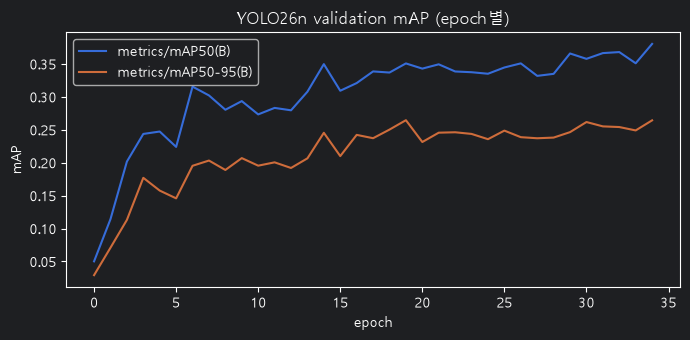

In [12]:
# [YOLO] YOLO26n 학습 (저장 모델 재사용)
from ultralytics import YOLO
YOLO_RUNS = MODEL_DIR / "yolo_runs"
YOLO_BEST = MODEL_DIR / "lens_yolo26n.pt"
YOLO_META = MODEL_DIR / "lens_yolo26n.json"
yolo_signature = hashlib.sha256(json.dumps({"data": YOLO_DATA_SIGNATURE, "model": YOLO_MODEL, "epochs": YOLO_EPOCHS, "imgsz": YOLO_IMGSZ, "batch": YOLO_BATCH,
                                            "patience": YOLO_PATIENCE, "seed": SEED, "aug": "flipud0.5-fliplr0.5", "version": "lens-yolo-1"}).encode()).hexdigest()
if USE_SAVED_MODELS and YOLO_BEST.exists() and YOLO_META.exists() and json.loads(YOLO_META.read_text(encoding="utf-8")).get("signature") == yolo_signature:
    yolo_meta = json.loads(YOLO_META.read_text(encoding="utf-8"))
    print("lens_yolo26n → 데이터·설정이 같은 저장 모델 재사용")
else:
    trainer_model = YOLO(YOLO_MODEL)
    started = time.perf_counter()
    trainer_model.train(data=str(YOLO_YAML), epochs=YOLO_EPOCHS, patience=YOLO_PATIENCE, imgsz=YOLO_IMGSZ, batch=YOLO_BATCH, device=YOLO_DEVICE, workers=0,
                        seed=SEED, deterministic=True, project=str(YOLO_RUNS), name="lens_yolo26n", exist_ok=True, flipud=0.5, fliplr=0.5, plots=True, verbose=False)
    save_dir = Path(trainer_model.trainer.save_dir)
    shutil.copy2(save_dir / "weights" / "best.pt", YOLO_BEST)
    history = save_dir / "results.csv"
    if history.exists():
        shutil.copy2(history, MET_DIR / "lens_yolo26n_history.csv")
    yolo_meta = {"signature": yolo_signature, "training_seconds": time.perf_counter() - started, "epochs_completed": int(len(pd.read_csv(history))) if history.exists() else None,
                 "run_dir": str(save_dir), "base_model": YOLO_MODEL, "train_tiles": int((yolo_tiles.split == "train").sum())}
    save_json(YOLO_META, yolo_meta)
yolo = YOLO(str(YOLO_BEST))
YOLO_SHA = sha256_file(YOLO_BEST)
YOLO_VERSION = f"lens_yolo26n-{MODEL_VERSION_TAG}-{YOLO_SHA[:8]}"
yolo_meta["model_bytes"] = YOLO_BEST.stat().st_size
print({k: v for k, v in yolo_meta.items() if k != "signature"}, "/ 버전:", YOLO_VERSION)
history_file = MET_DIR / "lens_yolo26n_history.csv"
if history_file.exists():
    hist = pd.read_csv(history_file)
    hist.columns = [c.strip() for c in hist.columns]
    columns = [c for c in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"] if c in hist]
    if columns:
        ax = hist[columns].plot(figsize=(7, 3.5), title="YOLO26n validation mAP (epoch별)")
        ax.set(xlabel="epoch", ylabel="mAP")
        plt.tight_layout()
        plt.savefig(FIG_DIR / "yolo26n_training_curve.png", dpi=130)
        plt.show()

## PART 04. 검출 성능 (조각 단위, YOLO 표준 지표)
- **mAP50:** 예측 상자와 정답 상자가 50% 이상 겹치면 맞힌 것으로 보는 평균 정밀도
- **mAP50-95:** 겹침 기준을 50~95%로 올려 가며 평균(더 엄격)
- **결함 종류별 AP50:** 결함 종류를 맞히는 성능. Flash Particle(16개)·Hole(28개)은 정답이 적어 불안정합니다.

In [13]:
# [YOLO] validation·test 조각에서 YOLO 표준 검출 지표
det_rows = []
for split in ["val", "test"]:
    m = yolo.val(data=str(YOLO_YAML), split=split, imgsz=YOLO_IMGSZ, batch=YOLO_BATCH, device=YOLO_DEVICE, workers=0, plots=False, verbose=False,
                 project=str(YOLO_RUNS), name=f"eval_{split}", exist_ok=True)
    row = {"split": split, "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map), "precision": float(m.box.mp), "recall": float(m.box.mr)}
    try:
        for i, c in enumerate(m.box.ap_class_index):
            row[f"AP50_{YOLO_CLASSES[int(c)]}"] = float(m.box.ap50[i])
    except Exception as error:
        row["per_class_note"] = f"결함 종류별 AP를 읽지 못함: {error}"
    det_rows.append(row)
yolo_detection = pd.DataFrame(det_rows)
yolo_detection.to_csv(MET_DIR / "lens_yolo26n_detection_metrics.csv", index=False, encoding="utf-8-sig")
print(yolo_detection.round(4).T)

Ultralytics 8.4.218  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 7 255H)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 1860.9±435.0 MB/s, size: 370.7 KB)
val: Scanning C:\Project\Ai_Source\FoldedVision_Lens\data\yolo_lens\labels\val.cache... 151 images, 80 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 151/151  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.2it/s 16.2s0.4s
                   all        151        132      0.385      0.334      0.351      0.265
Speed: 5.8ms preprocess, 78.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.218  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core Ultra 7 255H)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 203.5±83.2 MB/s, size: 373.4 KB)
val: Scanning C:\Project\Ai_Source\Folded

## PART 05. 02의 CNN과 같은 기준으로 비교 (256 구역 단위)
- 사진을 640 조각으로 나눠 YOLO로 검출하고, 상자를 사진 좌표로 되돌립니다.
- **256 구역 점수 = 그 구역에 걸친 YOLO 상자 신뢰도의 최댓값**(상자가 없으면 0)
- 02와 **같은 구역 정답**에서, validation으로 불량 구역 Recall 95% 경계(NG)와 99% 경계(OK 상한)를 정하고 test를 한 번만 채점합니다.
- 02 노트북의 비교표(`lens_decision_source_patch_comparison.csv`)가 있으면 CNN 행을 불러와 나란히 놓습니다.

                                           0                      1
판정 방식                Final CNN 구역 점수 최댓값(02)  YOLO26n 구역 점수 최댓값(03)
val AP                                0.3492                 0.8105
test AP                               0.4187                 0.8083
test ROC-AUC                           0.756                 0.9398
NG 경계(val Recall95)                   0.2865                 0.0308
test Recall                           0.9206                 0.9516
test 정상 구역 오검출률                       0.6542                 0.2511
놓친 불량 구역(FN)                              46                     28
잘못 잡은 정상 구역(FP)                         1852                    711
YOLO 사진당 검출 시간(CPU): 560 ms


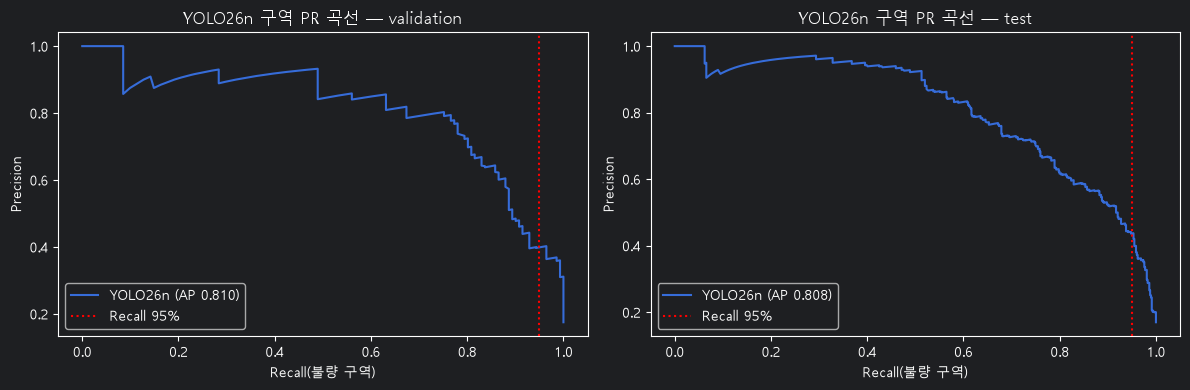

In [14]:
# [YOLO] 사진 단위 조각 검출 → 256 구역 점수 → CNN과 같은 지표
def yolo_detect(work_rgb, conf=YOLO_CONF_MIN):
    # 작업 배율 사진을 640 조각으로 검출 → 사진 좌표 상자 [x0, y0, x1, y1, 신뢰도, 클래스]
    valid = valid_region(work_rgb)
    padded = pad_to(work_rgb, YOLO_TILE)
    tiles = tile_positions(work_rgb.shape, valid)
    boxes = []
    for i in range(0, len(tiles), YOLO_BATCH):
        chunk = tiles[i:i + YOLO_BATCH]
        batch = [cv2.cvtColor(np.ascontiguousarray(padded[y:y + YOLO_TILE, x:x + YOLO_TILE]), cv2.COLOR_RGB2BGR) for y, x in chunk]  # Ultralytics는 BGR 배열을 받음
        for (y, x), result in zip(chunk, yolo.predict(batch, imgsz=YOLO_IMGSZ, conf=conf, device=YOLO_DEVICE, verbose=False)):
            if result.boxes is None or len(result.boxes) == 0:
                continue
            xyxy = result.boxes.xyxy.cpu().numpy()
            for (x0, y0, x1, y1), score, cls in zip(xyxy, result.boxes.conf.cpu().numpy(), result.boxes.cls.cpu().numpy()):
                boxes.append([x0 + x, y0 + y, x1 + x, y1 + y, float(score), int(cls)])
    return np.array(boxes, np.float32).reshape(-1, 6)

def patch_scores_from_boxes(boxes, positions):
    scores = np.zeros(len(positions), np.float32)
    if len(boxes):
        for j, (y, x) in enumerate(positions):
            hit = (boxes[:, 0] < x + PATCH) & (boxes[:, 2] > x) & (boxes[:, 1] < y + PATCH) & (boxes[:, 3] > y)
            if hit.any():
                scores[j] = boxes[hit, 4].max()
    return scores

YOLO_DETECTIONS, yolo_patch = {}, {}
started = time.perf_counter()
for split in ["validation", "test"]:
    rows = patch_table[(patch_table.split == split) & patch_table.use].reset_index(drop=True)
    scores = np.zeros(len(rows), np.float32)
    for key, part in rows.groupby("image_key"):
        if key not in YOLO_DETECTIONS:
            YOLO_DETECTIONS[key] = yolo_detect(lens_work[key]["image"])
        scores[part.index] = patch_scores_from_boxes(YOLO_DETECTIONS[key], list(zip(part.y, part.x)))
    yolo_patch[split] = {"y": rows.label.to_numpy(np.float32), "s": scores, "rows": rows}
yolo_seconds_per_image = (time.perf_counter() - started) / max(1, len(YOLO_DETECTIONS))

yv, sv = yolo_patch["validation"]["y"], yolo_patch["validation"]["s"]
yt, st = yolo_patch["test"]["y"], yolo_patch["test"]["s"]
YOLO_NG = threshold_for_recall(yv, sv, RECALL_TARGET)
YOLO_OK = min(YOLO_NG, threshold_for_recall(yv, sv, REVIEW_RECALL))
yolo_test = binary_metrics(yt, st, YOLO_NG)
yolo_row = {"판정 방식": "YOLO26n 구역 점수 최댓값(03)", "val AP": float(average_precision_score(yv, sv)), "test AP": yolo_test["average_precision"],
            "test ROC-AUC": yolo_test["roc_auc"], "NG 경계(val Recall95)": YOLO_NG, "test Recall": yolo_test["recall"],
            "test 정상 구역 오검출률": yolo_test["false_positive_rate"], "놓친 불량 구역(FN)": yolo_test["FN"], "잘못 잡은 정상 구역(FP)": yolo_test["FP"]}
cnn_file = MET_DIR / "lens_decision_source_patch_comparison.csv"
if cnn_file.exists():
    cnn_rows = pd.read_csv(cnn_file)
    cnn_rows = cnn_rows[cnn_rows["판정 방식"].str.contains("CNN")].assign(**{"판정 방식": "Final CNN 구역 점수 최댓값(02)"})
    model_comparison = pd.concat([cnn_rows, pd.DataFrame([yolo_row])], ignore_index=True)
else:
    print("02 노트북 비교표가 없어 YOLO만 표시합니다(02를 먼저 실행하면 CNN과 나란히 비교됩니다).")
    model_comparison = pd.DataFrame([yolo_row])
model_comparison.to_csv(MET_DIR / "lens_cnn_vs_yolo26n.csv", index=False, encoding="utf-8-sig")
print(model_comparison.round(4).T)
print(f"YOLO 사진당 검출 시간(CPU): {1000 * yolo_seconds_per_image:.0f} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, y, s) in zip(axes, [("validation", yv, sv), ("test", yt, st)]):
    precision, recall, _ = precision_recall_curve(y, s)
    ax.plot(recall, precision, label=f"YOLO26n (AP {average_precision_score(y, s):.3f})")
    ax.axvline(RECALL_TARGET, color="red", ls=":", label="Recall 95%")
    ax.set(title=f"YOLO26n 구역 PR 곡선 — {name}", xlabel="Recall(불량 구역)", ylabel="Precision")
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "yolo26n_patch_pr.png", dpi=130)
plt.show()

## PART 06. 사진 단위 판정과 검출 예시
- 사진 점수 = 그 사진 구역 점수의 최댓값 → OK / REVIEW / NG (02와 같은 방식)
- test 사진은 모두 결함 사진이라 **불량 사진 Recall만 실측**할 수 있습니다. 정상 사진 오검출률은 02와 같이 구역 오검출률로 **추정**만 합니다(구역끼리 독립이라는 가정).
- 그림: 초록 = 정답 결함 상자, 빨강 = NG 경계 이상 YOLO 상자(결함 종류·신뢰도 표시)

{
 "images": 52,
 "defect_images": 52,
 "normal_images": 0,
 "NG": 52,
 "REVIEW": 0,
 "OK": 0,
 "auto_ng_recall": 1.0,
 "not_ok_recall_including_review": 1.0,
 "defect_passed_as_ok": 0,
 "normal_false_positive_rate": null,
 "normal_false_positive_reason": "test에 공식 정상 사진 0장 — 측정 불가",
 "estimated_normal_image_fpr": 0.9999999999329999,
 "estimate_note": "추정: 1-(1-구역FPR 0.2511)^81 (정상 사진 0장이라 실측 불가)"
}


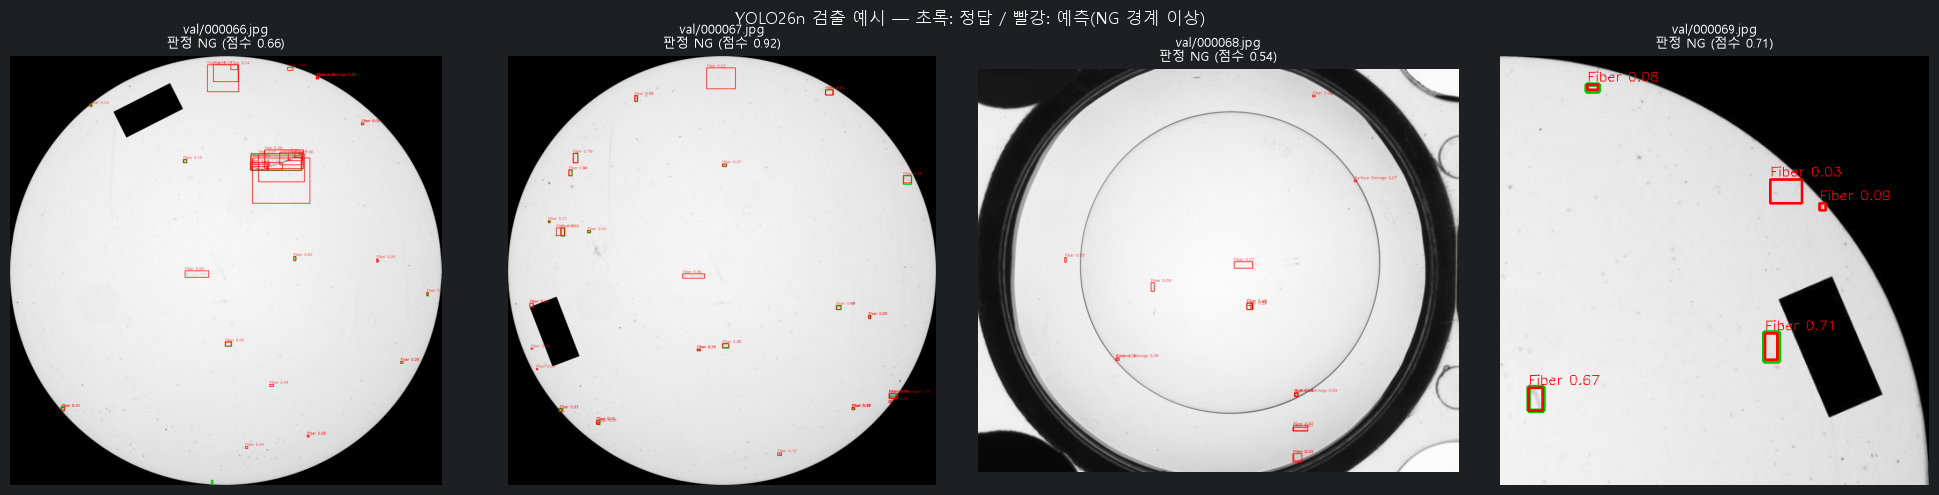

In [15]:
# 사진 단위 판정 + 검출 예시 그림
test_rows = yolo_patch["test"]["rows"]
yolo_image_scores = image_scores(test_rows, st)
yolo_image = {k: v for k, v in image_level_summary(yolo_image_scores, YOLO_OK, YOLO_NG).items() if not isinstance(v, (pd.Series, pd.DataFrame))}
patches_per_image = test_rows.groupby("image_key").size().median()
yolo_image["estimated_normal_image_fpr"] = 1 - (1 - yolo_test["false_positive_rate"]) ** patches_per_image
yolo_image["estimate_note"] = f"추정: 1-(1-구역FPR {yolo_test['false_positive_rate']:.4f})^{patches_per_image:.0f} (정상 사진 0장이라 실측 불가)"
print(json.dumps(yolo_image, ensure_ascii=False, indent=1))

examples = sorted(yolo_image_scores.index)[:4]
fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5))
for ax, key in zip(np.atleast_1d(axes), examples):
    canvas = lens_work[key]["image"].copy()
    for inst in lens_work[key]["instances"]:
        cv2.rectangle(canvas, (inst["x0"], inst["y0"]), (inst["x1"], inst["y1"]), (0, 200, 0), 3)
    for x0, y0, x1, y1, score, cls in YOLO_DETECTIONS[key]:
        if score >= YOLO_NG:
            cv2.rectangle(canvas, (int(x0), int(y0)), (int(x1), int(y1)), (255, 0, 0), 2)
            cv2.putText(canvas, f"{YOLO_CLASSES[int(cls)]} {score:.2f}", (int(x0), max(12, int(y0) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
    ax.imshow(canvas)
    ax.set_title(f"{key}\n판정 {decide(yolo_image_scores[key], YOLO_OK, YOLO_NG)} (점수 {yolo_image_scores[key]:.2f})", fontsize=9)
    ax.axis("off")
fig.suptitle("YOLO26n 검출 예시 — 초록: 정답 / 빨강: 예측(NG 경계 이상)")
fig.tight_layout()
fig.savefig(FIG_DIR / "yolo26n_test_examples.png", dpi=130)
plt.show()

## PART 07. 팀 통합용 `predict_lens_yolo(image)`와 결과 파일
`predict_lens_yolo`는 **저장된 `models/lens_yolo26n.pt`와 설정만으로** 추론합니다. 처리 순서는 다음과 같습니다.
1. 크기 묶음 확인 → 작업 배율로 축소
2. 640 조각 검출
3. 256 구역 점수의 최댓값
4. OK / REVIEW / NG

상자는 **원본 사진 좌표**로 되돌려 결함 종류와 함께 돌려줍니다. 적용 범위 밖 크기는 임의 점수 없이 REVIEW입니다.

| 파일 | 내용 |
|---|---|
| `outputs/integration/lens_yolo_predictions.csv` | test 52장 사진 판정(팀 공통 컬럼) |
| `outputs/integration/lens_yolo_metrics.json` | 구역·사진·검출 지표, CNN 비교 |
| `outputs/integration/lens_yolo_model_config.json` | 전처리·조각·경계·클래스 설정 |

In [16]:
# 팀 통합용 추론 함수 + 결과 파일
def predict_lens_yolo(image):
    # image: (높이, 너비, 3) uint8 RGB
    started = time.perf_counter()
    result = {"part_type": "Lens", "status": "REVIEW", "defect_score": None, "threshold": {"ok_upper": YOLO_OK, "ng": YOLO_NG}, "model_version": YOLO_VERSION,
              "boxes": [], "inference_ms": None, "reason": ""}
    image = np.asarray(image)
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    image = image[..., :3].astype(np.uint8)
    group = capture_group(image.shape[1], image.shape[0])
    if group not in LENS_SCALE:
        result["reason"] = f"학습에 없던 사진 크기({image.shape[1]}×{image.shape[0]}) — 적용 범위 밖"
    else:
        work, scale = to_work(image, group)
        positions = grid_positions(work.shape, valid_region(work))
        if not positions:
            result["reason"] = "렌즈 영역을 찾지 못했습니다."
        else:
            boxes = yolo_detect(work)
            score = float(patch_scores_from_boxes(boxes, positions).max())
            result.update({"defect_score": score, "status": decide(score, YOLO_OK, YOLO_NG), "reason": "YOLO26n 구역 점수 최댓값 기준 판정"})
            result["boxes"] = [{"class": YOLO_CLASSES[int(c)], "confidence": float(s), "x0": float(x0 / scale), "y0": float(y0 / scale), "x1": float(x1 / scale), "y1": float(y1 / scale)}
                               for x0, y0, x1, y1, s, c in boxes if s >= YOLO_NG]
            if RUN_MODE == "quick":
                result["status"], result["reason"] = "REVIEW", "quick 모델(기능 점검용) — 판정을 확정하지 않습니다."
    result["inference_ms"] = 1000 * (time.perf_counter() - started)
    return result

check = predict_lens_yolo(read_rgb(ROOT / lens_images.set_index("image_key").loc[split_keys("test")[0], "path"]))
odd = predict_lens_yolo(np.full((300, 400, 3), 200, np.uint8))
assert odd["status"] == "REVIEW" and odd["defect_score"] is None
print({k: v for k, v in check.items() if k != "boxes"}, "/ 상자", len(check["boxes"]), "개")
print("범위 밖:", odd["reason"])

image_ids = lens_images.set_index("image_key").image_id
yolo_predictions = pd.DataFrame({"image_id": yolo_image_scores.index.map(image_ids), "part_type": "Lens", "split": "test", "y_true": 1,
                                 "defect_score": yolo_image_scores.to_numpy(), "threshold": YOLO_NG, "y_pred": (yolo_image_scores.to_numpy() >= YOLO_NG).astype(int),
                                 "decision": [decide(s, YOLO_OK, YOLO_NG) for s in yolo_image_scores], "model_version": YOLO_VERSION})
yolo_predictions.to_csv(INTEG_DIR / "lens_yolo_predictions.csv", index=False, encoding="utf-8-sig")
save_json(INTEG_DIR / "lens_yolo_metrics.json", {
    "dataset_name": DATASET_NAME, "model": "YOLO26n (Ultralytics, COCO 사전학습 → Lens 640 조각 미세조정)", "model_version": YOLO_VERSION, "mode": RUN_MODE,
    "train_count": len(split_keys("train")), "validation_count": len(split_keys("validation")), "test_count": len(split_keys("test")),
    "threshold": YOLO_NG, "ok_upper_threshold": YOLO_OK, "threshold_basis": "validation 256 구역 불량 Recall 95%(NG) / 99%(OK 상한)",
    "patch_level_test": {k: yolo_test[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "TP", "FP", "TN", "FN", "false_positive_rate"]},
    "image_level_test": yolo_image, "detection_tiles": yolo_detection.to_dict("records"), "cnn_vs_yolo": model_comparison.to_dict("records"),
    "training": {k: v for k, v in yolo_meta.items() if k != "signature"}, "inference_ms_per_image_cpu": 1000 * yolo_seconds_per_image,
    "evaluation_note": "공식 Val(같은 렌즈 11장 제외) 52장. 정상 사진 0장이라 사진 단위 정상 오검출률은 추정치. 실제 생산라인 성능 아님."})
save_json(INTEG_DIR / "lens_yolo_model_config.json", {
    "model_name": "lens_yolo26n", "model_path": "models/lens_yolo26n.pt", "model_version": YOLO_VERSION, "base_model": YOLO_MODEL, "classes": YOLO_CLASSES,
    "color_mode": "RGB 입력 → Ultralytics에는 BGR로 변환해 전달", "preprocessing": {"capture_group_scale": LENS_SCALE, "interpolation": "cv2.INTER_AREA",
    "tile": YOLO_TILE, "tile_stride": YOLO_STRIDE, "tile_valid_min": YOLO_TILE_VALID_MIN, "imgsz": YOLO_IMGSZ, "pad": "640보다 작으면 오른쪽·아래 0 채움"},
    "decision_rule": "256 구역(02와 동일 격자) 점수 = 구역에 걸친 상자 신뢰도 최댓값 → 사진 점수 = 구역 최댓값 → score≥ng NG, score<ok_upper OK, 그 사이 REVIEW",
    "threshold": {"ok_upper": YOLO_OK, "ng": YOLO_NG}, "output_type": "신뢰도(0~1, 보정된 확률 아님)",
    "dataset_source": "VISION Datasets Lens (CC BY-NC 4.0)", "limitations": ["정상 렌즈 사진 0장", "결함 종류 Flash Particle·Hole은 정답 수가 적음", "공개 데이터 PoC — 실제 생산 성능 아님"]})
print(yolo_predictions.decision.value_counts().to_dict())
print("통합 파일:", sorted(p.name for p in INTEG_DIR.glob("lens_yolo_*")))

{'part_type': 'Lens', 'status': 'NG', 'defect_score': 0.6629241108894348, 'threshold': {'ok_upper': 0.019676731899380684, 'ng': 0.03077058494091034}, 'model_version': 'lens_yolo26n-v1-7ab74386', 'inference_ms': 2690.4936999999336, 'reason': 'YOLO26n 구역 점수 최댓값 기준 판정'} / 상자 39 개
범위 밖: 학습에 없던 사진 크기(400×300) — 적용 범위 밖
{'NG': 52}
통합 파일: ['lens_yolo_metrics.json', 'lens_yolo_model_config.json', 'lens_yolo_predictions.csv']


In [17]:
# (선택) YOLO 검사 화면 — 로컬 127.0.0.1:7863
if ENABLE_GRADIO:
    import gradio as gr
    def ui_yolo(image):
        if image is None:
            return "사진을 올려 주세요.", None
        r = predict_lens_yolo(image)
        canvas = image.copy()
        for b in r["boxes"]:
            cv2.rectangle(canvas, (int(b["x0"]), int(b["y0"])), (int(b["x1"]), int(b["y1"])), (255, 0, 0), max(2, image.shape[1] // 500))
        score = "없음" if r["defect_score"] is None else f"{r['defect_score']:.3f}"
        kinds = Counter(b["class"] for b in r["boxes"])
        return (f"## 판정: {r['status']}\n- 결함 점수: {score} / 경계 OK<{YOLO_OK:.3f}, NG≥{YOLO_NG:.3f}\n- 검출 결함: {dict(kinds) or '없음'}\n"
                f"- 사유: {r['reason']}\n- 모델: {r['model_version']} / {r['inference_ms']:.0f} ms"), canvas
    with gr.Blocks(title="Lens YOLO26n 검사") as yolo_demo:
        gr.Markdown("### FoldedVision AI — Lens YOLO26n 검사 (공개 데이터 PoC)")
        upload = gr.Image(type="numpy", label="Lens 사진")
        button = gr.Button("검사")
        verdict = gr.Markdown()
        shown = gr.Image(label="검출 결과(빨간 상자)")
        button.click(ui_yolo, upload, [verdict, shown])
    yolo_demo.launch(share=False, server_name="127.0.0.1", server_port=7863, inbrowser=True)

## 보고서
이번 실행에서 계산된 값만 `outputs/metrics/lens_yolo_report.md`에 씁니다.

In [18]:
# YOLO 보고서(실측값만)
def fmt(v, pct=False):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "N/A"
    return f"{100 * v:.1f}%" if pct else (f"{v:.4f}" if isinstance(v, float) else str(v))
lines = [f"# Lens YOLO26n 보고 ({RUN_MODE})", "", "> " + ("**quick 모드: 기능 점검용 — 성능으로 쓰지 말 것**" if QUICK else "full 모드 실측 결과") + " / 공개 데이터 PoC", "",
         "## 모델", f"- YOLO26n(Ultralytics, COCO 사전학습) → Lens 640 조각으로 미세조정 / 클래스 {len(YOLO_CLASSES)}개: {', '.join(YOLO_CLASSES)}",
         f"- 학습 조각: {int((yolo_tiles.split == 'train').sum())}개 / 학습 epoch: {yolo_meta.get('epochs_completed')} / 학습 시간: {fmt(yolo_meta.get('training_seconds'))}초",
         "", "## 검출 지표 (조각 단위)", "| split | mAP50 | mAP50-95 | Precision | Recall |", "|---|---|---|---|---|"]
lines += [f"| {r['split']} | {fmt(r['mAP50'])} | {fmt(r['mAP50-95'])} | {fmt(r['precision'])} | {fmt(r['recall'])} |" for r in det_rows]
per_class = {k[5:]: v for k, v in det_rows[-1].items() if k.startswith("AP50_")}
lines += [f"- test 결함 종류별 AP50: " + (", ".join(f"{k} {v:.3f}" for k, v in per_class.items()) or "N/A"), "",
          "## 02 CNN과 비교 (test 256 구역, 경계 = validation Recall 95%)", "| 방식 | test AP | ROC-AUC | Recall | 정상 구역 오검출률 |", "|---|---|---|---|---|"]
lines += [f"| {r['판정 방식']} | {fmt(r['test AP'])} | {fmt(r['test ROC-AUC'])} | {fmt(r['test Recall'], True)} | {fmt(r['test 정상 구역 오검출률'], True)} |" for r in model_comparison.to_dict("records")]
lines += ["", f"## 사진 단위 (test 결함 사진 {yolo_image['images']}장)", f"- 자동 NG {yolo_image['NG']} / REVIEW {yolo_image['REVIEW']} / OK {yolo_image['OK']} → 불량 자동 NG Recall {fmt(yolo_image['auto_ng_recall'], True)}",
          f"- 정상 사진 오검출률: 실측 불가(정상 사진 0장). {yolo_image['estimate_note']} = {fmt(yolo_image['estimated_normal_image_fpr'], True)}",
          f"- CPU 추론: 사진당 약 {1000 * yolo_seconds_per_image:.0f} ms", "",
          "## 한계", "- 정상 렌즈 사진이 없어 정상 오검출률은 추정치", "- 정답에 표시되지 않은 작은 먼지 점이 많아 정상 구역 정답에 잡음이 있음(02의 구역 확인 결과 참고)",
          "- 공개 데이터 PoC — 실제 생산 성능 아님"]
(MET_DIR / "lens_yolo_report.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

# Lens YOLO26n 보고 (full)

> full 모드 실측 결과 / 공개 데이터 PoC

## 모델
- YOLO26n(Ultralytics, COCO 사전학습) → Lens 640 조각으로 미세조정 / 클래스 5개: Fiber, Flash Particle, Hole, Surface Damage, Tear
- 학습 조각: 552개 / 학습 epoch: 35 / 학습 시간: 5603.2771초

## 검출 지표 (조각 단위)
| split | mAP50 | mAP50-95 | Precision | Recall |
|---|---|---|---|---|
| val | 0.3506 | 0.2646 | 0.3852 | 0.3335 |
| test | 0.4056 | 0.2657 | 0.3930 | 0.4293 |
- test 결함 종류별 AP50: Fiber 0.597, Flash Particle 0.071, Hole 0.880, Surface Damage 0.139, Tear 0.340

## 02 CNN과 비교 (test 256 구역, 경계 = validation Recall 95%)
| 방식 | test AP | ROC-AUC | Recall | 정상 구역 오검출률 |
|---|---|---|---|---|
| Final CNN 구역 점수 최댓값(02) | 0.4187 | 0.7560 | 92.1% | 65.4% |
| YOLO26n 구역 점수 최댓값(03) | 0.8083 | 0.9398 | 95.2% | 25.1% |

## 사진 단위 (test 결함 사진 52장)
- 자동 NG 52 / REVIEW 0 / OK 0 → 불량 자동 NG Recall 100.0%
- 정상 사진 오검출률: 실측 불가(정상 사진 0장). 추정: 1-(1-구역FPR 0.2511)^81 (정상 사진 0장이라 실측 불가) = 100.0%
- CPU 추론: 사진당 약 560 ms

## 한계
- 정상 렌즈 사진이 없어 정상 오검출률은 추정치
- 정답에 표시되지 않은 작은 먼지 점